# Embedding analysis

Frozen embeddings from each encoder (HecVL, SurgVLP, PeskaVLP, SurgCLIP, SurgMotion300M): how much phase information they carry before any training. Reads cached embeddings only; encoding runs through the `encode-frames` task.

## Setup

Imports, paths, models, sampling rates and preprocessor.

In [1]:
import warnings

warnings.filterwarnings("ignore", category=FutureWarning, module="timm")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, f1_score, silhouette_score
from sklearn.neighbors import KNeighborsClassifier

from surgphase.config import ANNOTATIONS_DIR, EMBEDDINGS_DIR, MODELS, PHASE_GROUP_FILE, ROOT_DIR, UNLABELLED
from surgphase.data import EncodingSpec, PhaseMapper, load_phase_group, load_surgeries
from surgphase.eval.metrics import segments
from surgphase.eval.splits import leave_one_surgery_out
from surgphase.inference import load_embeddings
from surgphase.viz import CATEGORICAL, SEQUENTIAL, phase_colors, style_axes
from surgphase.viz.style import GRIDLINE, INK, MUTED_INK, SECONDARY_INK, SURFACE

ANNOTATION_ID = "default"
ANNOTATIONS_FILE = ANNOTATIONS_DIR / ANNOTATION_ID / "annotated_frames.csv"
ANALYSIS_MODELS = MODELS
ANALYSIS_FPS = [1.0, 15.0]
SURGERY_IDS = None
PREPROCESSOR = "letterbox"
CLIP_STRIDE = 1
NEUTRAL_PHASE = "P0"
MAX_POINTS = 4000
PROJECTION_POINTS = 3000
KNN_NEIGHBOURS = 15
KNN_TRAIN_LIMIT = 20000
KNN_TEST_LIMIT = 5000
LAG_SECONDS = 1.0
SEED = 0

DIVERGING = LinearSegmentedColormap.from_list("surgphase_diverging", ["#256abf", "#f0efec", "#e34948"])
MODEL_COLORS = {model: CATEGORICAL[index] for index, model in enumerate(MODELS)}


def even_indices(count, limit):
    return np.unique(np.linspace(0, count - 1, min(count, limit)).round().astype(int))


def normalise(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True).clip(min=1e-12)


def key_label(key):
    return f"{key[0]} @ {key[1]:g} fps"


def clean_axes(ax, grid_axis="y"):
    style_axes(ax)
    if grid_axis:
        ax.grid(axis=grid_axis, color=GRIDLINE, linewidth=0.6)
    ax.set_axisbelow(True)


def figure_legend(fig, axes):
    handles = {}
    for ax in np.ravel(axes):
        for handle, label in zip(*ax.get_legend_handles_labels(), strict=True):
            handles.setdefault(label, handle)
    fig.legend(
        list(handles.values()), list(handles), loc="outside lower center", ncol=min(len(handles), 6),
        frameon=False, labelcolor=SECONDARY_INK,
    )

## Load embeddings

Cached embeddings per model, surgery and FPS, aligned with the per-frame phase labels. Missing combinations are skipped, not encoded.

In [3]:
phase_group = load_phase_group(PHASE_GROUP_FILE)
mapper = PhaseMapper(phase_group)
phase_ids = mapper.get_all_phase_ids()
phase_names = [f"{phase.id} {phase.name}" for phase in mapper.phases]
colors = phase_colors(len(phase_ids), neutral_phase=mapper.map_to_index(NEUTRAL_PHASE))

surgeries = {fps: load_surgeries(ANNOTATIONS_FILE, phase_group, ROOT_DIR, fps, SURGERY_IDS) for fps in ANALYSIS_FPS}
surgery_ids = sorted({s for by_id in surgeries.values() for s in by_id})
surgery_colors = {s: CATEGORICAL[i % len(CATEGORICAL)] for i, s in enumerate(surgery_ids)}

specs = {model: EncodingSpec.for_model(model, PREPROCESSOR, CLIP_STRIDE) for model in ANALYSIS_MODELS}
embeddings, missing = {}, []
for model, spec in specs.items():
    for fps, by_id in surgeries.items():
        for surgery_id, surgery in by_id.items():
            try:
                tensor = load_embeddings(EMBEDDINGS_DIR, spec, surgery)
            except FileNotFoundError:
                missing.append((model, fps, surgery_id))
                continue
            embeddings.setdefault((model, fps), {})[surgery_id] = tensor.float().numpy()

keys = sorted(embeddings, key=lambda key: (MODELS.index(key[0]), key[1]))


def keys_at(fps):
    return [key for key in keys if key[1] == fps]


plot_fps = [fps for fps in ANALYSIS_FPS if keys_at(fps)]


def stacked(key, labelled_only=True):
    parts = embeddings[key]
    by_id = surgeries[key[1]]
    x = np.concatenate([parts[s] for s in parts])
    y = np.concatenate([by_id[s].labels for s in parts])
    groups = np.concatenate([np.full(len(parts[s]), s) for s in parts])
    if labelled_only:
        keep = y != UNLABELLED
        return x[keep], y[keep], groups[keep]
    return x, y, groups


def sample(key, limit, labelled_only=True):
    x, y, groups = stacked(key, labelled_only)
    chosen = even_indices(len(x), limit)
    return normalise(x[chosen]), y[chosen], groups[chosen]


print(f"loaded {len(keys)} model/fps combinations: {', '.join(map(key_label, keys))}")
if missing:
    print(f"{len(missing)} model/fps/surgery combinations not cached yet (see inventory)")

loaded 10 model/fps combinations: HecVL @ 1 fps, HecVL @ 15 fps, SurgVLP @ 1 fps, SurgVLP @ 15 fps, PeskaVLP @ 1 fps, PeskaVLP @ 15 fps, SurgCLIP @ 1 fps, SurgCLIP @ 15 fps, SurgMotion300M @ 1 fps, SurgMotion300M @ 15 fps
8 model/fps/surgery combinations not cached yet (see inventory)


## Embedding inventory

Which model, FPS and surgery combinations are cached, with embedding dimension, clip length and frame counts checked against the labels.

In [4]:
inventory_rows = []
for model in ANALYSIS_MODELS:
    for fps, by_id in surgeries.items():
        for surgery_id, surgery in by_id.items():
            x = embeddings.get((model, fps), {}).get(surgery_id)
            inventory_rows.append(
                {
                    "model": model,
                    "fps": fps,
                    "surgery": surgery_id,
                    "cached": x is not None,
                    "clip": specs[model].clip_length,
                    "dim": None if x is None else x.shape[1],
                    "frames": None if x is None else len(x),
                    "labels": len(surgery.labels),
                }
            )
inventory = pd.DataFrame(inventory_rows)
inventory["aligned"] = inventory["frames"] == inventory["labels"]

misaligned = inventory[inventory["cached"] & ~inventory["aligned"]]
if len(misaligned):
    print("embedding and label counts differ:")
    display(misaligned)

coverage = inventory.pivot_table(index="model", columns="fps", values="cached", aggfunc="sum").reindex(ANALYSIS_MODELS)
coverage.columns = [f"{fps:g} fps" for fps in coverage.columns]
dims = pd.DataFrame(
    {
        "clip": {model: spec.clip_length for model, spec in specs.items()},
        "dim": inventory.dropna(subset=["dim"]).groupby("model")["dim"].first(),
    }
)
print(f"surgeries cached out of {len(surgery_ids)} per model and fps")
coverage.join(dims).astype("Int64")

surgeries cached out of 7 per model and fps


,1 fps,15 fps,clip,dim
model,,,,
HecVL,7,7,1,768
SurgVLP,7,7,1,768
PeskaVLP,7,7,1,768
SurgCLIP,7,6,16,768
SurgMotion300M,5,2,64,1024


## Embedding statistics

Norms, per-dimension variance and PCA explained variance per model. Shows anisotropy and how many dimensions are actually used.

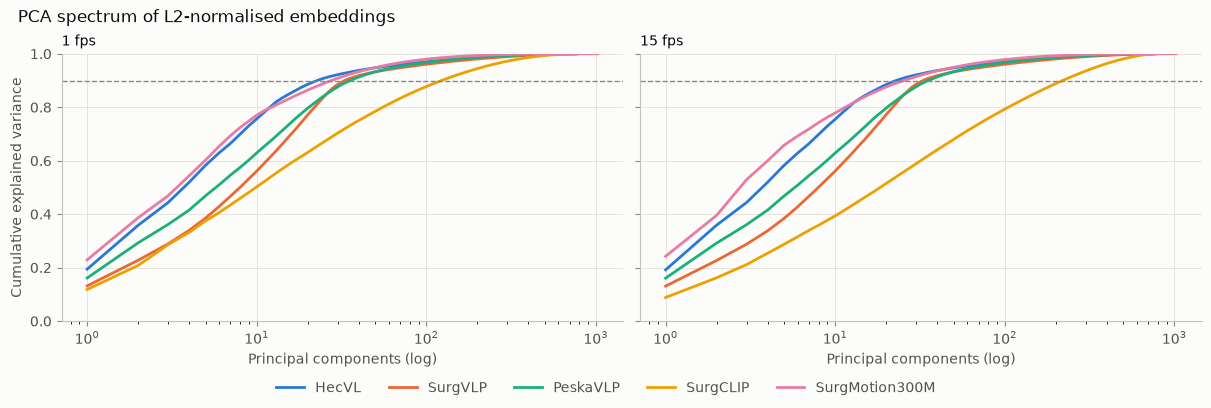

dim  mean norm  norm cv  mean pair cosine  \
model          fps                                                
HecVL          1.0    768   3.368000    0.085             0.794   
               15.0   768   3.366000    0.085             0.793   
SurgVLP        1.0    768   4.979000    0.094             0.469   
               15.0   768   4.986000    0.094             0.470   
PeskaVLP       1.0    768   8.040000    0.152             0.505   
               15.0   768   8.054000    0.151             0.500   
SurgCLIP       1.0    768  25.687000    0.007             0.500   
               15.0   768  25.648001    0.007             0.483   
SurgMotion300M 1.0   1024  88.129997    0.021             0.910   
               15.0  1024  91.274002    0.023             0.877   

                     PCs for 90% var  participation ratio  
model          fps                                         
HecVL          1.0                23               11.087  
               15.0               23               11.108  
SurgVLP        1.0                34               21.127  
               15.0               33               21.187  
PeskaVLP       1.0                36               15.906  
               15.0               36               15.965  
SurgCLIP       1.0               123               26.130  
               15.0              220               41.966  
SurgMotion300M 1.0                28                9.939  
               15.0               26                8.866

In [5]:
stats_rows, explained = [], {}
for key in keys:
    x, _, _ = stacked(key)
    chosen = even_indices(len(x), MAX_POINTS)
    raw = x[chosen]
    unit = normalise(raw)
    rng = np.random.default_rng(SEED)
    pairs = rng.integers(0, len(unit), size=(MAX_POINTS, 2))
    pca = PCA(random_state=SEED).fit(unit)
    ratio = pca.explained_variance_ratio_
    explained[key] = np.cumsum(ratio)
    stats_rows.append(
        {
            "model": key[0],
            "fps": key[1],
            "dim": x.shape[1],
            "mean norm": np.linalg.norm(raw, axis=1).mean(),
            "norm cv": np.linalg.norm(raw, axis=1).std() / np.linalg.norm(raw, axis=1).mean(),
            "mean pair cosine": np.einsum("ij,ij->i", unit[pairs[:, 0]], unit[pairs[:, 1]]).mean(),
            "PCs for 90% var": int(np.searchsorted(np.cumsum(ratio), 0.9) + 1),
            "participation ratio": ratio.sum() ** 2 / (ratio**2).sum(),
        }
    )
embedding_stats = pd.DataFrame(stats_rows).set_index(["model", "fps"])

fig, axes = plt.subplots(
    1, len(plot_fps), figsize=(6 * len(plot_fps), 4), layout="constrained", sharey=True, squeeze=False
)
for ax, fps in zip(axes[0], plot_fps, strict=True):
    clean_axes(ax, grid_axis="both")
    for key in keys_at(fps):
        curve = explained[key]
        ax.plot(np.arange(1, len(curve) + 1), curve, color=MODEL_COLORS[key[0]], linewidth=2, label=key[0])
    ax.axhline(0.9, color=MUTED_INK, linewidth=1, linestyle="--")
    ax.set_xscale("log")
    ax.set_ylim(0, 1)
    ax.set_xlabel("Principal components (log)")
    ax.set_title(f"{fps:g} fps", loc="left", fontsize=10)
axes[0, 0].set_ylabel("Cumulative explained variance")
figure_legend(fig, axes)
fig.suptitle("PCA spectrum of L2-normalised embeddings", x=0.01, ha="left", color=INK)
plt.show()

embedding_stats.round(3)

## 2D projections

PCA and t-SNE of the frames per model, coloured by phase and by surgery.

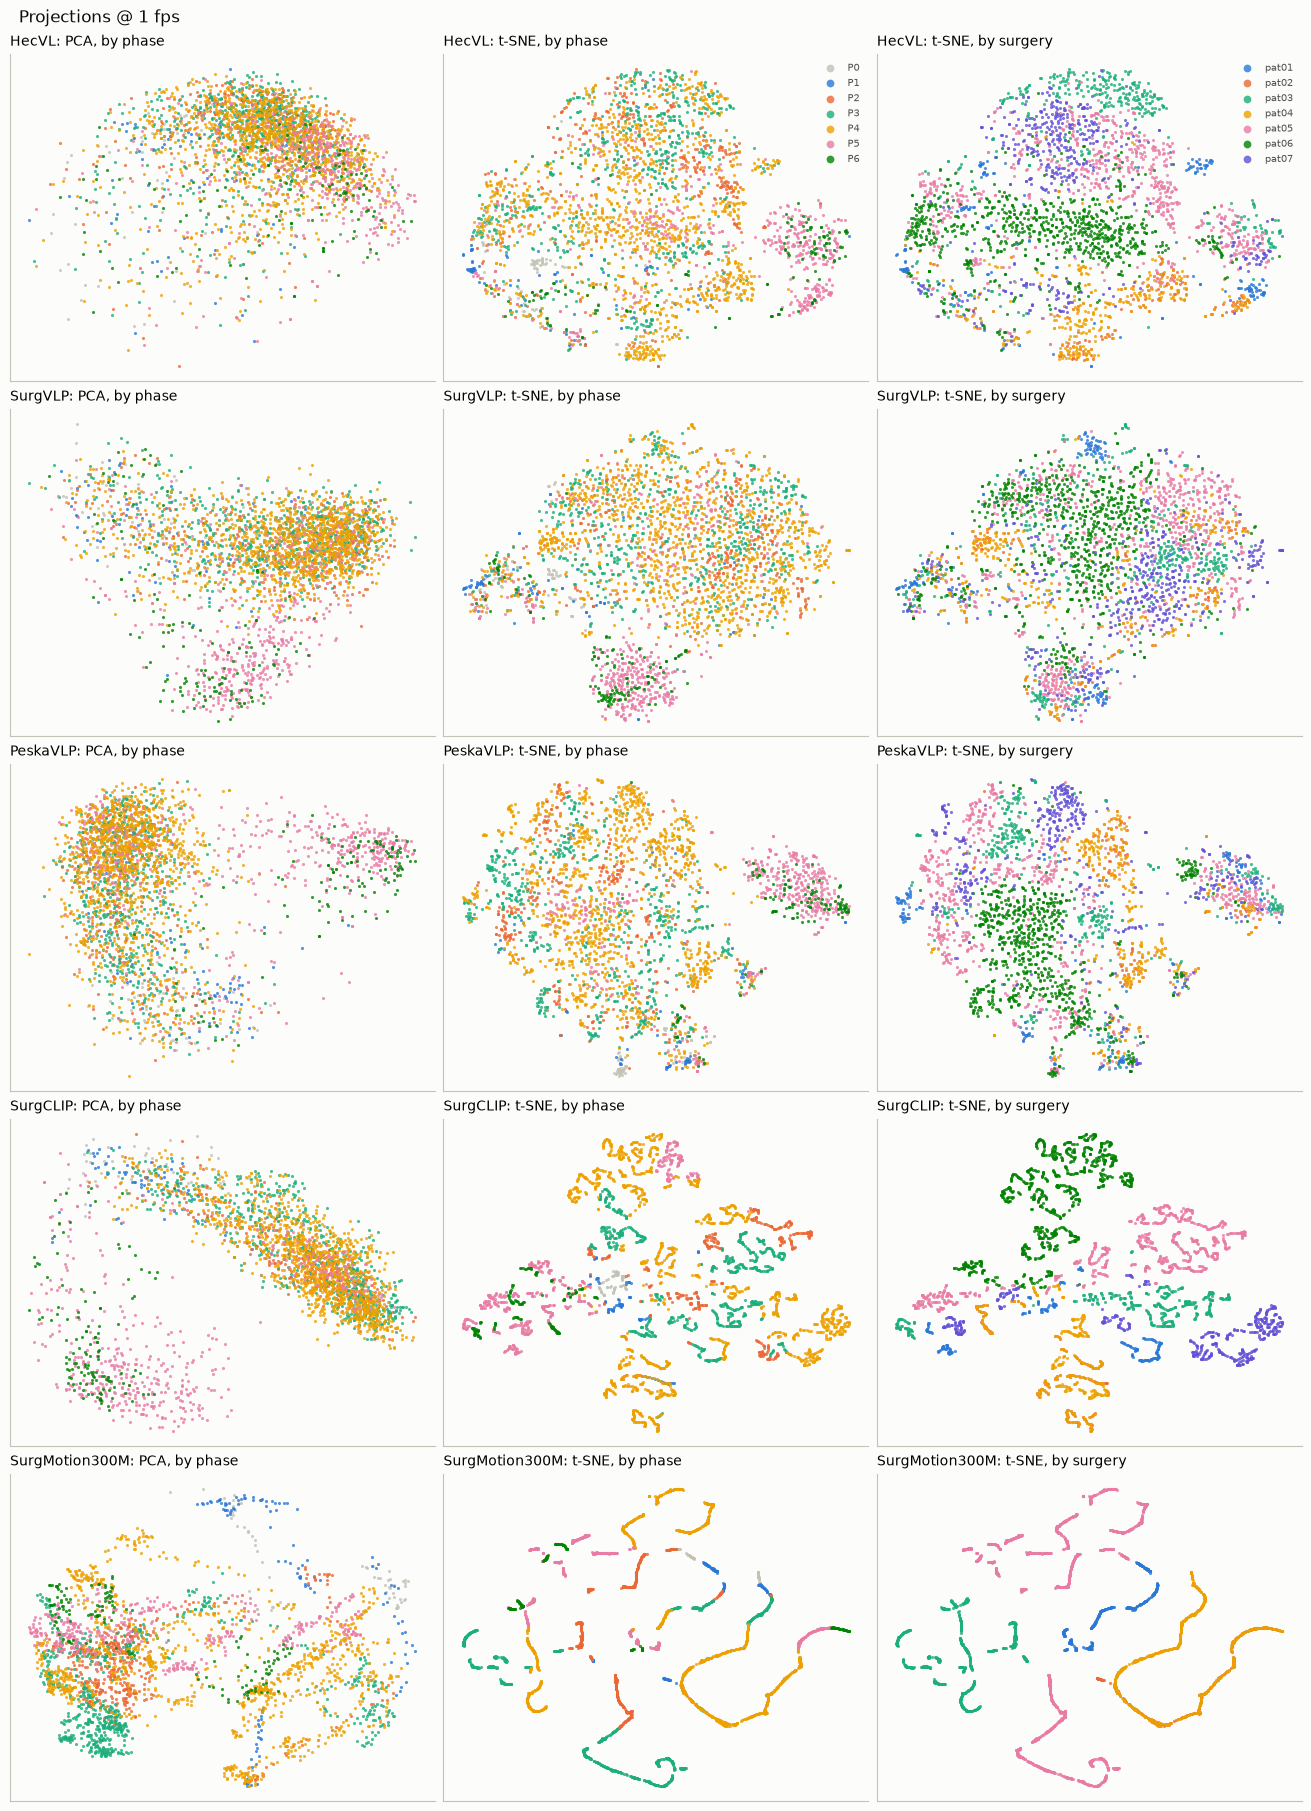

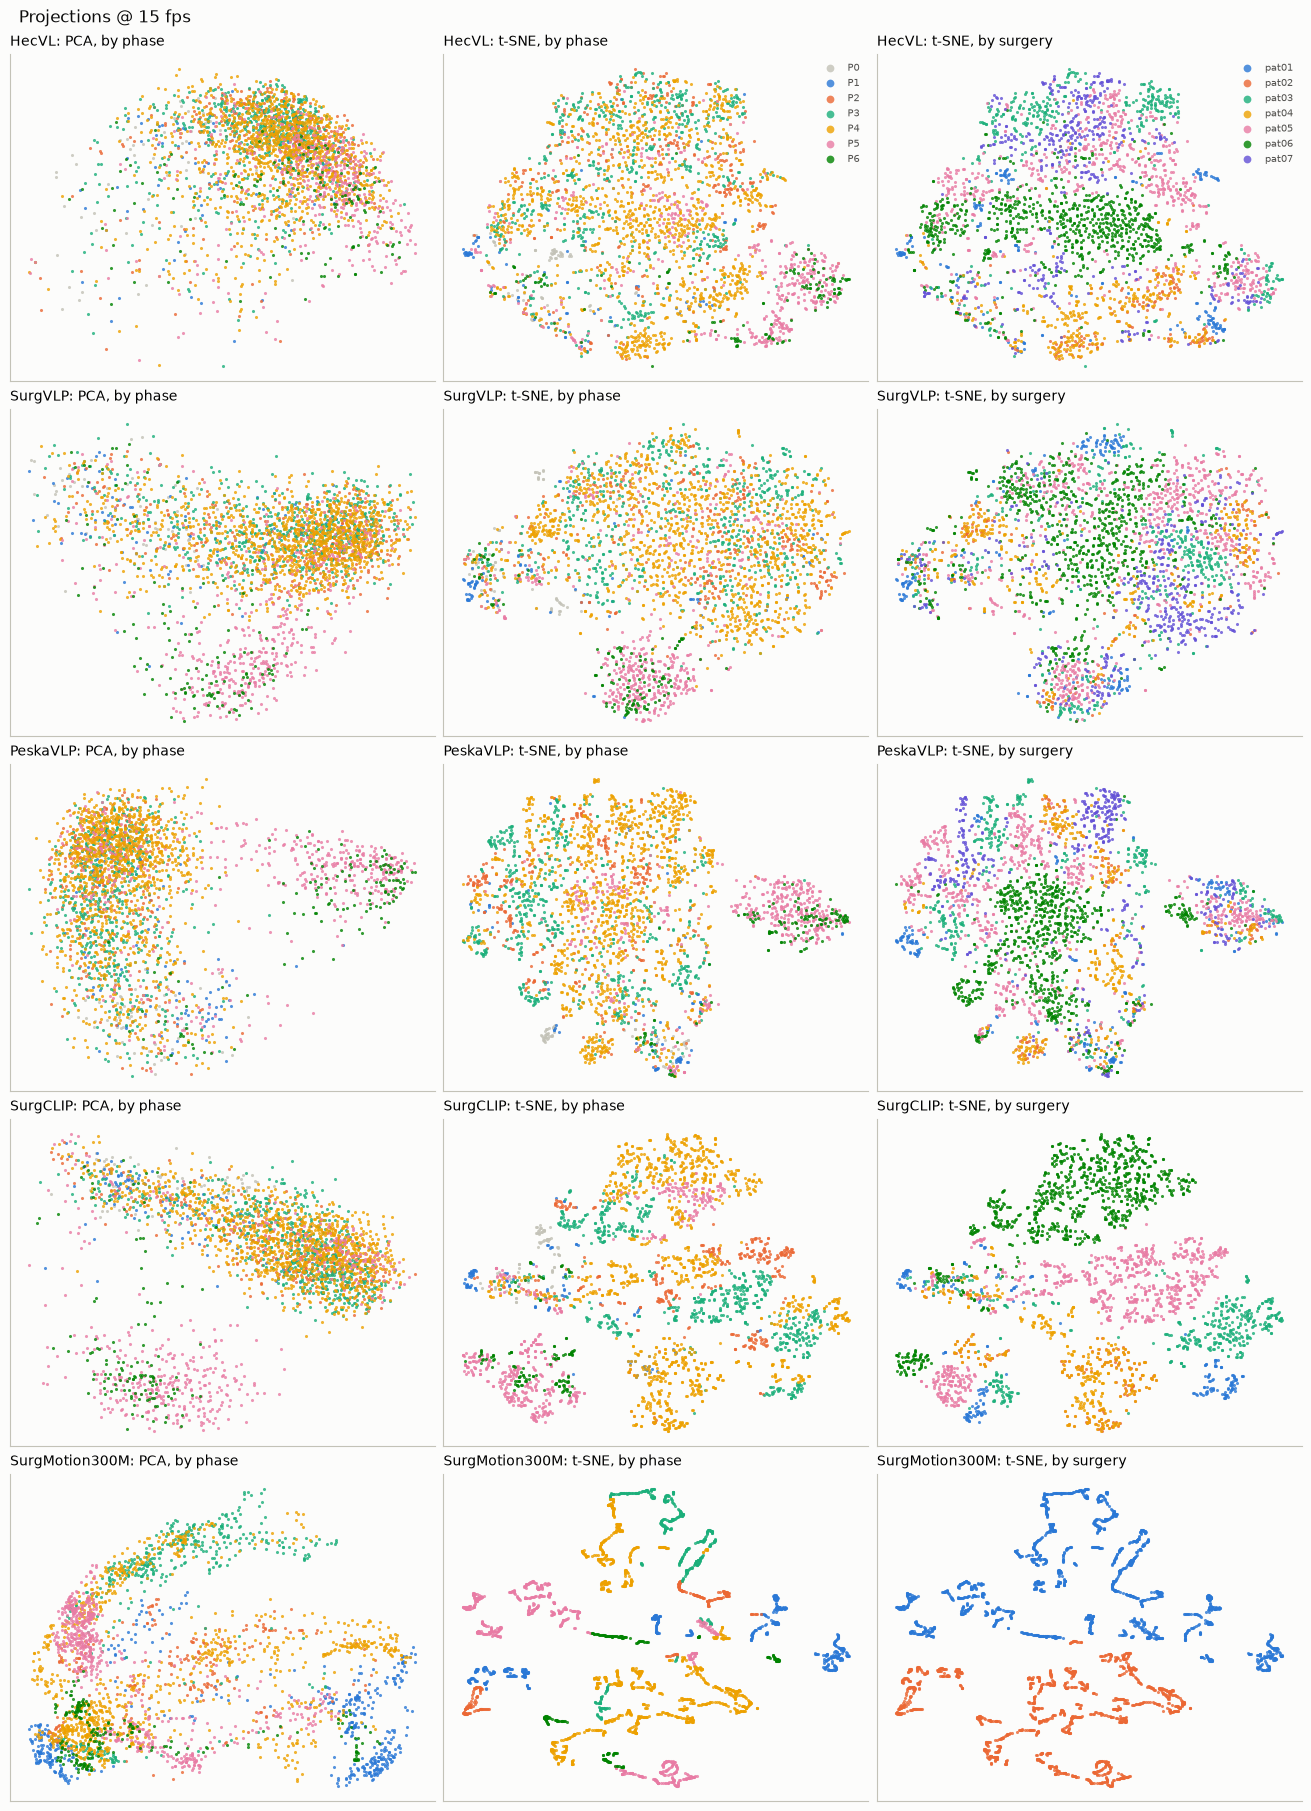

In [6]:
for fps in plot_fps:
    plot_keys = keys_at(fps)
    fig, axes = plt.subplots(
        len(plot_keys), 3, figsize=(13, 3.6 * len(plot_keys)), layout="constrained", squeeze=False
    )
    for row, key in enumerate(plot_keys):
        x, y, groups = sample(key, PROJECTION_POINTS)
        pca_points = PCA(n_components=2, random_state=SEED).fit_transform(x)
        tsne_points = TSNE(
            n_components=2, metric="cosine", init="pca", perplexity=30, random_state=SEED
        ).fit_transform(x)
        views = (
            (pca_points, y, "PCA, by phase"),
            (tsne_points, y, "t-SNE, by phase"),
            (tsne_points, groups, "t-SNE, by surgery"),
        )
        for ax, (points, values, title) in zip(axes[row], views, strict=True):
            style_axes(ax)
            palette = colors if values is y else None
            for value in (range(len(phase_ids)) if values is y else surgery_ids):
                chosen = values == value
                if chosen.any():
                    ax.scatter(
                        points[chosen, 0], points[chosen, 1], s=5, linewidth=0, alpha=0.8,
                        color=palette[value] if palette else surgery_colors[value],
                        label=phase_ids[value] if palette else value,
                    )
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(f"{key[0]}: {title}", loc="left", fontsize=10)
        if row == 0:
            for column in (1, 2):
                axes[row, column].legend(
                    loc="upper right", fontsize=7, markerscale=2.5, frameon=False, labelcolor=SECONDARY_INK
                )
    fig.suptitle(f"Projections @ {fps:g} fps", x=0.01, ha="left", color=INK)
    plt.show()


## Surgery versus phase structure

Whether embeddings cluster more by surgery than by phase: silhouette scores for both groupings per model.

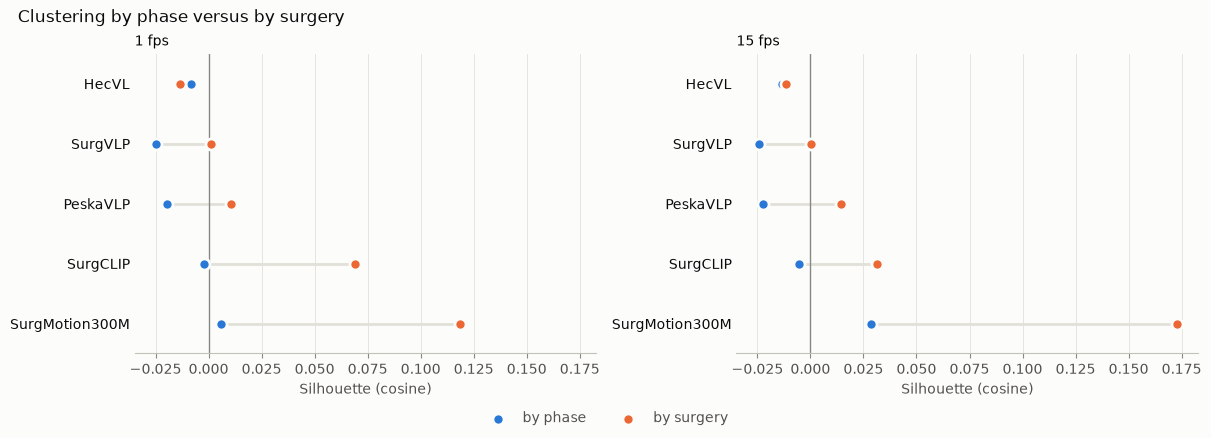

by phase  by surgery  phase - surgery
model          fps                                        
HecVL          1.0     -0.008      -0.014            0.005
               15.0    -0.014      -0.011           -0.002
SurgVLP        1.0     -0.025       0.001           -0.026
               15.0    -0.024       0.000           -0.025
PeskaVLP       1.0     -0.019       0.010           -0.030
               15.0    -0.022       0.014           -0.037
SurgCLIP       1.0     -0.002       0.069           -0.071
               15.0    -0.005       0.032           -0.037
SurgMotion300M 1.0      0.006       0.119           -0.113
               15.0     0.028       0.173           -0.144

In [7]:
silhouette_rows = []
for key in keys:
    x, y, groups = sample(key, MAX_POINTS)
    silhouette_rows.append(
        {
            "model": key[0],
            "fps": key[1],
            "by phase": silhouette_score(x, y, metric="cosine") if len(np.unique(y)) > 1 else np.nan,
            "by surgery": silhouette_score(x, groups, metric="cosine") if len(np.unique(groups)) > 1 else np.nan,
        }
    )
silhouettes = pd.DataFrame(silhouette_rows).set_index(["model", "fps"])
silhouettes["phase - surgery"] = silhouettes["by phase"] - silhouettes["by surgery"]

rows_needed = max(len(keys_at(fps)) for fps in plot_fps)
fig, axes = plt.subplots(
    1, len(plot_fps), figsize=(6 * len(plot_fps), 0.5 * rows_needed + 1.8),
    layout="constrained", sharex=True, squeeze=False,
)
for ax, fps in zip(axes[0], plot_fps, strict=True):
    plot_table = silhouettes.xs(fps, level="fps")
    clean_axes(ax, grid_axis="x")
    positions = np.arange(len(plot_table))
    ax.hlines(positions, plot_table["by phase"], plot_table["by surgery"], color=GRIDLINE, linewidth=2)
    ax.scatter(plot_table["by phase"], positions, s=64, color=CATEGORICAL[0], edgecolor=SURFACE, linewidth=2, zorder=3, label="by phase")
    ax.scatter(plot_table["by surgery"], positions, s=64, color=CATEGORICAL[1], edgecolor=SURFACE, linewidth=2, zorder=3, label="by surgery")
    ax.axvline(0, color=MUTED_INK, linewidth=1)
    ax.set_yticks(positions, labels=plot_table.index)
    ax.set_ylim(rows_needed - 0.5, -0.5)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0, labelcolor=INK)
    ax.set_xlabel("Silhouette (cosine)")
    ax.set_title(f"{fps:g} fps", loc="left", fontsize=10)
figure_legend(fig, axes)
fig.suptitle("Clustering by phase versus by surgery", x=0.01, ha="left", color=INK)
plt.show()

silhouettes.round(3)

## Phase separability

Leave-one-surgery-out k-nearest-neighbour accuracy and macro F1 per model, as a training-free probe of phase information.

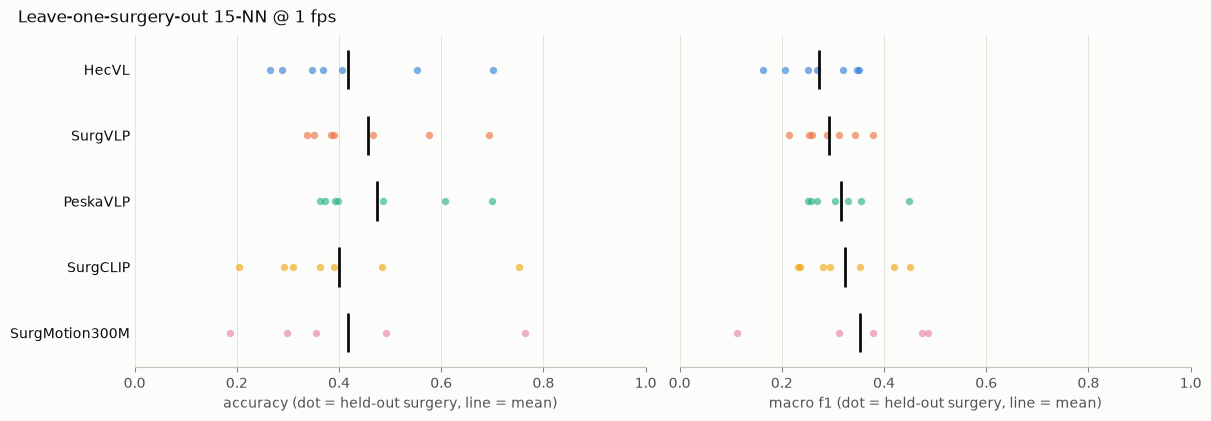

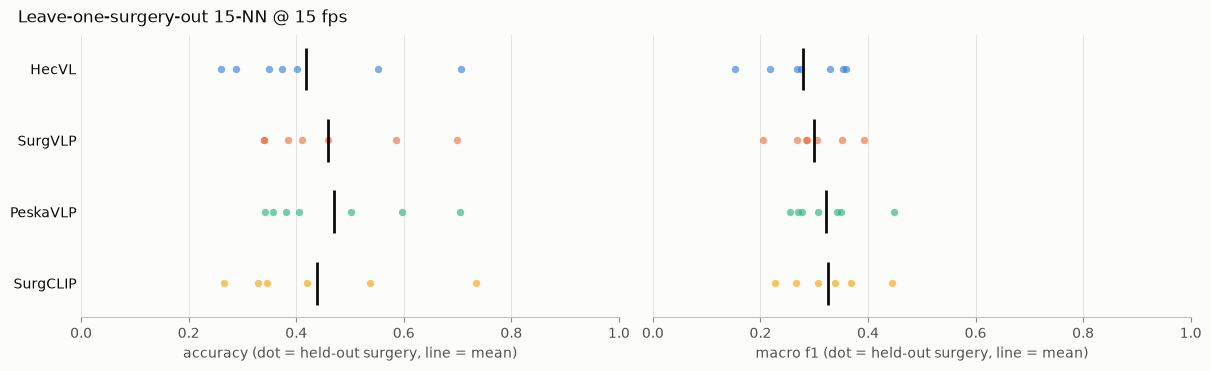

accuracy        macro f1       
                        mean    std     mean    std
model          fps                                 
HecVL          1.0     0.418  0.156    0.272  0.072
               15.0    0.419  0.158    0.280  0.076
PeskaVLP       1.0     0.474  0.131    0.316  0.070
               15.0    0.470  0.137    0.322  0.067
SurgCLIP       1.0     0.399  0.178    0.324  0.087
               15.0    0.439  0.172    0.325  0.077
SurgMotion300M 1.0     0.418  0.222    0.352  0.153
SurgVLP        1.0     0.457  0.133    0.292  0.057
               15.0    0.460  0.135    0.299  0.060

In [8]:
knn_rows = []
for key in keys:
    x_all, y_all, groups_all = stacked(key)
    ids = [s for s in surgery_ids if s in embeddings[key]]
    if len(ids) < 3:
        continue
    for fold in leave_one_surgery_out(ids):
        train_ids = [*fold.train, fold.val]
        train = np.flatnonzero(np.isin(groups_all, train_ids))
        test = np.flatnonzero(groups_all == fold.test)
        train = train[even_indices(len(train), KNN_TRAIN_LIMIT)]
        test = test[even_indices(len(test), KNN_TEST_LIMIT)]
        classifier = KNeighborsClassifier(n_neighbors=KNN_NEIGHBOURS, n_jobs=-1)
        classifier.fit(normalise(x_all[train]), y_all[train])
        predicted = classifier.predict(normalise(x_all[test]))
        knn_rows.append(
            {
                "model": key[0],
                "fps": key[1],
                "test": fold.test,
                "accuracy": accuracy_score(y_all[test], predicted),
                "macro f1": f1_score(y_all[test], predicted, average="macro", zero_division=0),
            }
        )
knn = pd.DataFrame(knn_rows, columns=["model", "fps", "test", "accuracy", "macro f1"])
knn_summary = knn.groupby(["model", "fps"])[["accuracy", "macro f1"]].agg(["mean", "std"])

for fps in ANALYSIS_FPS:
    plot_knn = knn[knn["fps"] == fps]
    plot_models = [m for m in MODELS if m in set(plot_knn["model"])]
    if not plot_models:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.5 * len(plot_models) + 1.6), layout="constrained", sharey=True)
    for ax, metric in zip(axes, ("accuracy", "macro f1"), strict=True):
        clean_axes(ax, grid_axis="x")
        for position, model in enumerate(plot_models):
            values = plot_knn.loc[plot_knn["model"] == model, metric].to_numpy()
            ax.scatter(values, np.full(len(values), position), s=28, color=MODEL_COLORS[model], alpha=0.6, linewidth=0)
            ax.vlines(values.mean(), position - 0.3, position + 0.3, color=INK, linewidth=2)
        ax.set_xlim(0, 1)
        ax.set_xlabel(f"{metric} (dot = held-out surgery, line = mean)")
        ax.spines["left"].set_visible(False)
        ax.tick_params(axis="y", length=0, labelcolor=INK)
    axes[0].set_yticks(range(len(plot_models)), labels=plot_models)
    axes[0].invert_yaxis()
    fig.suptitle(f"Leave-one-surgery-out {KNN_NEIGHBOURS}-NN @ {fps:g} fps", x=0.01, ha="left", color=INK)
    plt.show()

knn_summary.round(3)

## Phase centroid similarity

Cosine similarity between phase centroids per model. Which phases the encoders cannot tell apart.

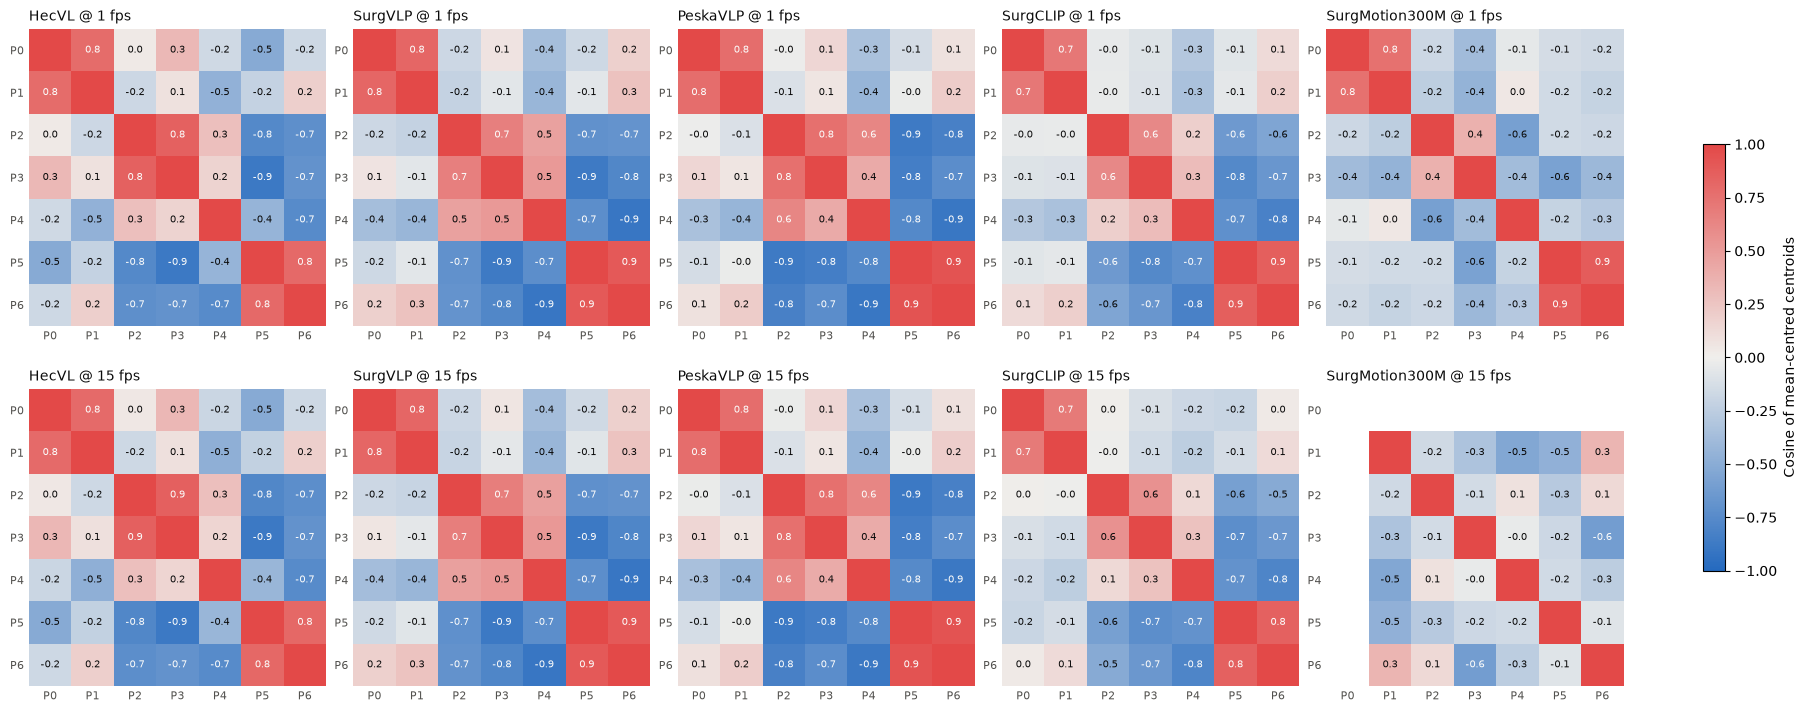

most similar phase pairs per model and fps


,HecVL @ 1 fps,SurgVLP @ 1 fps,PeskaVLP @ 1 fps,SurgCLIP @ 1 fps,SurgMotion300M @ 1 fps,HecVL @ 15 fps,SurgVLP @ 15 fps,PeskaVLP @ 15 fps,SurgCLIP @ 15 fps,SurgMotion300M @ 15 fps
closest,P2-P3 (0.85),P5-P6 (0.89),P5-P6 (0.93),P5-P6 (0.87),P5-P6 (0.88),P2-P3 (0.85),P5-P6 (0.89),P5-P6 (0.93),P5-P6 (0.85),P1-P6 (0.35)
2nd,P5-P6 (0.80),P0-P1 (0.81),P0-P1 (0.77),P0-P1 (0.71),P0-P1 (0.75),P5-P6 (0.81),P0-P1 (0.82),P0-P1 (0.78),P0-P1 (0.70),P2-P6 (0.13)
3rd,P0-P1 (0.79),P2-P3 (0.67),P2-P3 (0.76),P2-P3 (0.62),P2-P3 (0.37),P0-P1 (0.79),P2-P3 (0.68),P2-P3 (0.76),P2-P3 (0.56),P2-P4 (0.08)


In [9]:
heat_models = [model for model in ANALYSIS_MODELS if any(key[0] == model for key in keys)]
fig, axes = plt.subplots(
    len(plot_fps), len(heat_models), figsize=(3.4 * len(heat_models) + 1, 3.6 * len(plot_fps)),
    layout="constrained", squeeze=False,
)
centroid_similarity = {}
for row, fps in enumerate(plot_fps):
    for column, model in enumerate(heat_models):
        ax = axes[row, column]
        key = (model, fps)
        if key not in embeddings:
            ax.axis("off")
            continue
        x, y, _ = stacked(key)
        unit = normalise(x)
        centred = unit - unit.mean(axis=0)
        present = np.flatnonzero(np.bincount(y, minlength=len(phase_ids)))
        centroids = normalise(np.stack([centred[y == index].mean(axis=0) for index in present]))
        similarity = np.full((len(phase_ids), len(phase_ids)), np.nan)
        similarity[np.ix_(present, present)] = centroids @ centroids.T
        centroid_similarity[key] = pd.DataFrame(similarity, index=phase_ids, columns=phase_ids)
        image = ax.imshow(similarity, cmap=DIVERGING, vmin=-1, vmax=1)
        for i in range(len(phase_ids)):
            for j in range(len(phase_ids)):
                value = similarity[i, j]
                if i != j and np.isfinite(value):
                    ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=7,
                            color=SURFACE if abs(value) > 0.6 else INK)
        ax.set_xticks(range(len(phase_ids)), labels=phase_ids, fontsize=8)
        ax.set_yticks(range(len(phase_ids)), labels=phase_ids, fontsize=8)
        ax.tick_params(length=0, colors=MUTED_INK, labelcolor=SECONDARY_INK)
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_title(key_label(key), loc="left", fontsize=10, color=INK)
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.6, label="Cosine of mean-centred centroids")
plt.show()

upper = np.triu(np.ones((len(phase_ids), len(phase_ids)), dtype=bool), k=1)
closest = pd.DataFrame(
    {
        key_label(key): [
            f"{a}-{b} ({value:.2f})"
            for (a, b), value in table.where(upper).stack().sort_values(ascending=False).head(3).items()
        ]
        for key, table in centroid_similarity.items()
    },
    index=["closest", "2nd", "3rd"],
)
print("most similar phase pairs per model and fps")
closest

## Temporal smoothness

Cosine similarity between consecutive frames over time, within phases versus across phase boundaries. Image encoders against clip encoders.

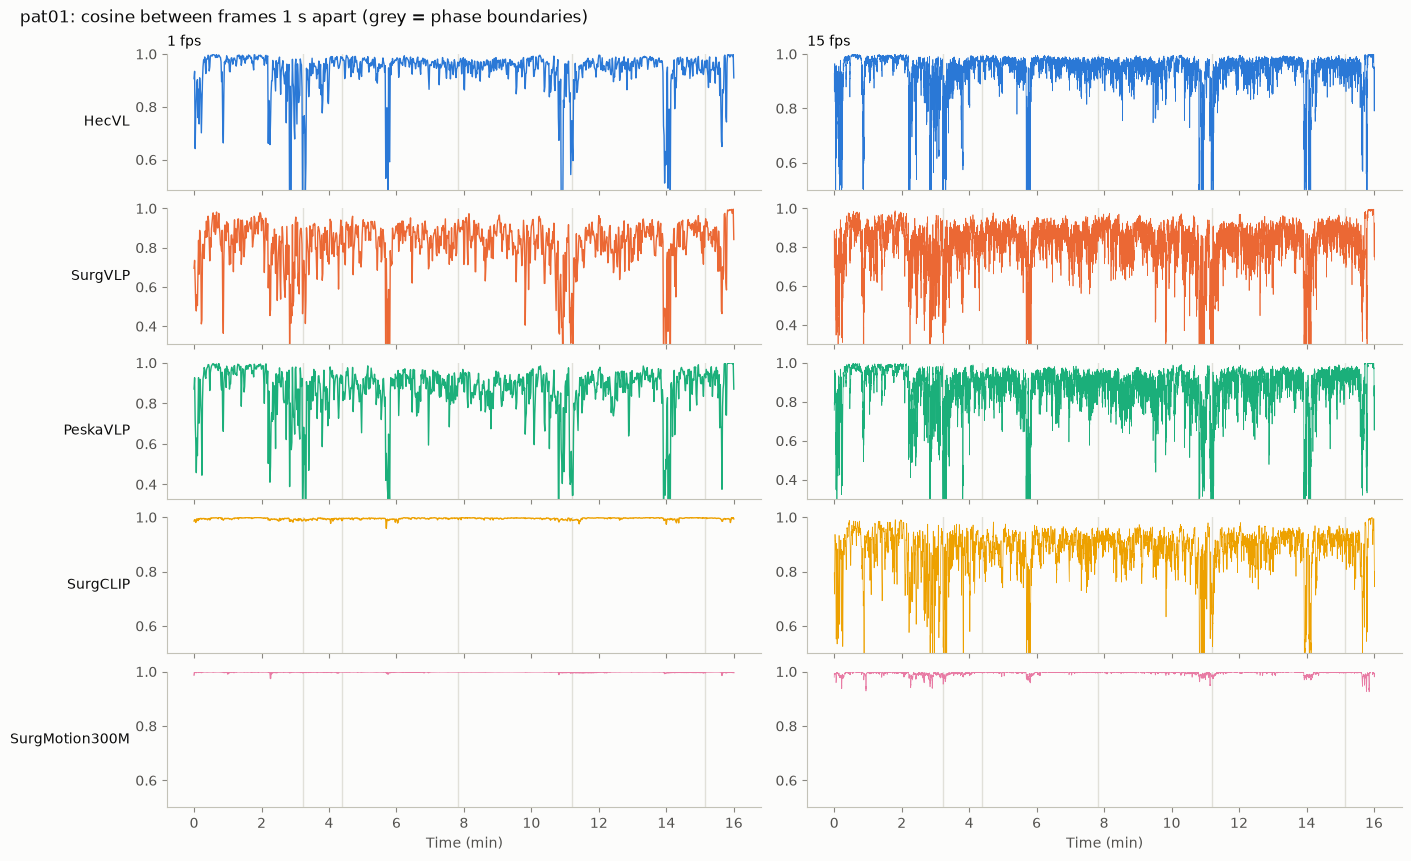

lag frames  within phase  across boundary  within p10  \
model          fps                                                           
HecVL          1.0            1         0.958            0.844       0.874   
               15.0          15         0.958            0.892       0.873   
SurgVLP        1.0            1         0.794            0.636       0.609   
               15.0          15         0.795            0.728       0.610   
PeskaVLP       1.0            1         0.878            0.638       0.700   
               15.0          15         0.879            0.744       0.702   
SurgCLIP       1.0            1         0.995            0.994       0.991   
               15.0          15         0.881            0.820       0.770   
SurgMotion300M 1.0            1         0.998            0.998       0.996   
               15.0          15         0.997            0.995       0.988   

                       gap  
model          fps          
HecVL          1.0   0.114  
               15.0  0.066  
SurgVLP        1.0   0.158  
               15.0  0.067  
PeskaVLP       1.0   0.239  
               15.0  0.135  
SurgCLIP       1.0   0.001  
               15.0  0.061  
SurgMotion300M 1.0   0.001  
               15.0  0.002

In [10]:
smoothness_rows, traces = [], {}
for key in keys:
    lag = max(1, round(key[1] * LAG_SECONDS))
    within, across = [], []
    for surgery_id, x in embeddings[key].items():
        unit = normalise(x)
        labels = surgeries[key[1]][surgery_id].labels
        similarity = np.einsum("ij,ij->i", unit[:-lag], unit[lag:])
        both = (labels[:-lag] != UNLABELLED) & (labels[lag:] != UNLABELLED)
        same = labels[:-lag] == labels[lag:]
        within.append(similarity[both & same])
        across.append(similarity[both & ~same])
        traces[(key, surgery_id)] = similarity
    within, across = np.concatenate(within), np.concatenate(across)
    smoothness_rows.append(
        {
            "model": key[0],
            "fps": key[1],
            "lag frames": lag,
            "within phase": np.median(within),
            "across boundary": np.median(across) if len(across) else np.nan,
            "within p10": np.percentile(within, 10),
        }
    )
smoothness = pd.DataFrame(smoothness_rows).set_index(["model", "fps"])
smoothness["gap"] = smoothness["within phase"] - smoothness["across boundary"]

example = surgery_ids[0]
trace_models = [
    model for model in ANALYSIS_MODELS
    if any(example in embeddings.get((model, fps), {}) for fps in plot_fps)
]
fig, axes = plt.subplots(
    len(trace_models), len(plot_fps), figsize=(7 * len(plot_fps), 1.5 * len(trace_models) + 1),
    layout="constrained", sharex=True, squeeze=False,
)
for column, fps in enumerate(plot_fps):
    boundaries = segments(surgeries[fps][example].labels).starts[1:] if example in surgeries[fps] else []
    for row, model in enumerate(trace_models):
        ax = axes[row, column]
        key = (model, fps)
        if example not in embeddings.get(key, {}):
            ax.axis("off")
            continue
        clean_axes(ax, grid_axis=None)
        trace = traces[(key, example)]
        minutes = np.arange(len(trace)) / fps / 60
        for boundary in boundaries:
            ax.axvline(boundary / fps / 60, color=GRIDLINE, linewidth=1)
        ax.plot(minutes, trace, color=MODEL_COLORS[model], linewidth=1 if fps <= 1 else 0.5)
        ax.set_ylim(min(0.5, np.percentile(trace, 1)), 1)
        if all(not other.axison for other in axes[row, :column]):
            ax.set_ylabel(model, rotation=0, ha="right", va="center", color=INK)
        if row == 0:
            ax.set_title(f"{fps:g} fps", loc="left", fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("Time (min)")
fig.suptitle(
    f"{example}: cosine between frames {LAG_SECONDS:g} s apart (grey = phase boundaries)",
    x=0.01, ha="left", color=INK,
)
plt.show()

smoothness.round(3)

## Effect of sampling rate

1 fps against 15 fps: whether denser sampling changes the statistics, smoothness and separability above.

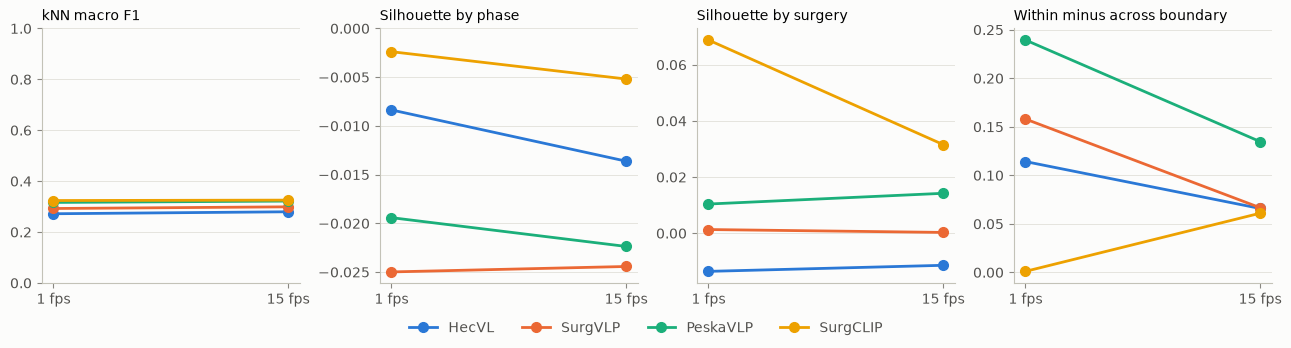

macro f1  by phase  by surgery  within phase    gap  \
model    fps                                                         
HecVL    1.0      0.272    -0.008      -0.014         0.958  0.114   
         15.0     0.280    -0.014      -0.011         0.958  0.066   
PeskaVLP 1.0      0.316    -0.019       0.010         0.878  0.239   
         15.0     0.322    -0.022       0.014         0.879  0.135   
SurgCLIP 1.0      0.324    -0.002       0.069         0.995  0.001   
         15.0     0.325    -0.005       0.032         0.881  0.061   
SurgVLP  1.0      0.292    -0.025       0.001         0.794  0.158   
         15.0     0.299    -0.024       0.000         0.795  0.067   

               participation ratio  
model    fps                        
HecVL    1.0                11.087  
         15.0               11.108  
PeskaVLP 1.0                15.906  
         15.0               15.965  
SurgCLIP 1.0                26.130  
         15.0               41.966  
SurgVLP  1.0                21.127  
         15.0               21.187

In [11]:
fps_metrics = (
    knn_summary.xs("mean", axis=1, level=1)[["macro f1"]]
    .join(silhouettes[["by phase", "by surgery"]])
    .join(smoothness[["within phase", "gap"]])
    .join(embedding_stats[["participation ratio"]])
)
compared = [model for model in MODELS if fps_metrics.index.get_level_values("model").tolist().count(model) > 1]

panels = ["macro f1", "by phase", "by surgery", "gap"]
titles = ["kNN macro F1", "Silhouette by phase", "Silhouette by surgery", "Within minus across boundary"]
fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.4), layout="constrained")
fps_positions = {fps: index for index, fps in enumerate(ANALYSIS_FPS)}
for ax, column, title in zip(axes, panels, titles, strict=True):
    clean_axes(ax)
    for model in compared:
        series = fps_metrics.xs(model, level="model")[column].dropna()
        ax.plot([fps_positions[fps] for fps in series.index], series.to_numpy(), marker="o", markersize=7,
                linewidth=2, color=MODEL_COLORS[model], label=model)
    low, high = ax.get_ylim()
    ax.set_ylim((0, 1) if column == "macro f1" else (min(low, 0), max(high, 0)))
    ax.set_xticks(range(len(ANALYSIS_FPS)), labels=[f"{fps:g} fps" for fps in ANALYSIS_FPS])
    ax.set_title(title, loc="left", fontsize=10)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=len(compared),
           frameon=False, labelcolor=SECONDARY_INK)
plt.show()

if not compared:
    print("no model is cached at more than one fps yet")
fps_metrics.loc[[key for key in fps_metrics.index if key[0] in compared]].round(3)

## Model comparison

Summary table of the metrics above, one row per model and FPS.

In [12]:
comparison = (
    embedding_stats[["dim", "PCs for 90% var", "participation ratio", "mean pair cosine"]]
    .join(silhouettes)
    .join(knn_summary.xs("mean", axis=1, level=1).add_prefix("kNN "))
    .join(smoothness[["within phase", "across boundary", "gap"]].add_prefix("smooth "))
)
comparison.insert(0, "clip", [specs[model].clip_length for model in comparison.index.get_level_values("model")])
comparison.insert(1, "surgeries", [len(embeddings[key]) for key in comparison.index])
highlight = [column for column in ("kNN accuracy", "kNN macro f1", "by phase") if comparison[column].notna().any()]
comparison.style.format(precision=3).background_gradient(cmap=SEQUENTIAL, subset=highlight)